<a href="https://colab.research.google.com/github/binary-cpu/chokepoint-tracker/blob/main/05_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chokepoint Traffic: Route Substitution and Shift Timing

Data snapshot: through 2026-10-11, accessed 2026-10-14.

Source: UN Global Platform; IMF PortWatch

## A. Retrieve Data

rows: 79548 | chokepoints: 28 | span: 2019-01-01 to 2026-10-11
duplicate (portid, date) rows: 0
chokepoints with missing days: 0
columns: ['date', 'year', 'month', 'day', 'portid', 'portname', 'n_container', 'n_dry_bulk', 'n_general_cargo', 'n_roro', 'n_tanker', 'n_cargo', 'n_total', 'capacity_container', 'capacity_dry_bulk', 'capacity_general_cargo', 'capacity_roro', 'capacity_tanker', 'capacity_cargo', 'capacity', 'ObjectId']
matched names: ['Bab el-Mandeb Strait', 'Cape of Good Hope', 'Strait of Hormuz', 'Suez Canal']


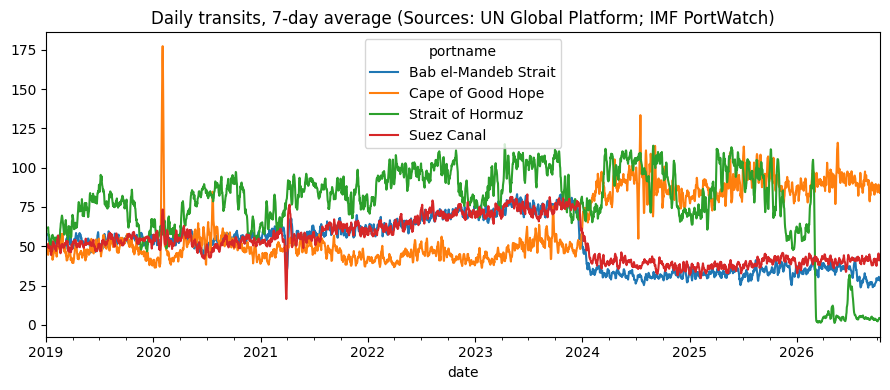

In [1]:
%pip -q install requests pandas matplotlib
import requests, pandas as pd
import matplotlib.pyplot as plt

BASE = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer"
CHOKE_DB = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/PortWatch_chokepoints_database/FeatureServer"

def layer_url(base):
    info = requests.get(base, params={"f": "json"}, timeout=60).json()
    # Safely get layer ID; if 'layers' is empty or missing, assume the first layer is 0 or base already contains it
    layers = info.get('layers', [])
    if layers:
        layer_id = layers[0]['id']
        return f"{base}/{layer_id}/query"
    elif base.endswith(tuple(str(i) for i in range(10))):
        return f"{base}/query"
    else:
        return f"{base}/0/query"

def fetch_all(base, order=None, page=1000):
    url, rows, offset = layer_url(base), [], 0
    while True:
        params = {"where": "1=1", "outFields": "*", "returnGeometry": "false",
                  "resultOffset": offset, "resultRecordCount": page, "f": "json"}
        if order:
            params["orderByFields"] = order
        r = requests.get(url, params=params, timeout=120).json()
        if "error" in r:
            raise RuntimeError(r["error"])
        feats = r.get("features", [])
        rows += [f["attributes"] for f in feats]
        if not feats or not r.get("exceededTransferLimit"):
            break
        offset += len(feats)
    return pd.DataFrame(rows)

daily = fetch_all(BASE, order="date,portid")
chokes = fetch_all(CHOKE_DB, order="portid")
if pd.api.types.is_numeric_dtype(daily["date"]):
    daily["date"] = pd.to_datetime(daily["date"], unit="ms")
else:
    daily["date"] = pd.to_datetime(daily["date"])

print("rows:", len(daily), "| chokepoints:", daily.portid.nunique(),
      "| span:", daily.date.min().date(), "to", daily.date.max().date())
print("duplicate (portid, date) rows:", int(daily.duplicated(["portid", "date"]).sum()))
span_days = (daily.date.max() - daily.date.min()).days + 1
print("chokepoints with missing days:", int((daily.groupby("portid").date.nunique() < span_days).sum()))
print("columns:", list(daily.columns))

pick = daily[daily.portname.str.contains("Suez|Bab|Hormuz|Cape of Good Hope", case=False, na=False)]
print("matched names:", sorted(pick.portname.unique()))
piv = pick.pivot(index="date", columns="portname", values="n_total").rolling(7).mean()
piv.plot(figsize=(9, 4), title="Daily transits, 7-day average (Sources: UN Global Platform; IMF PortWatch)")
plt.tight_layout(); plt.show()


## B. Load Data into DuckDB

In [2]:
%pip -q install duckdb
import duckdb
con = duckdb.connect()
con.register("daily", daily)
con.sql("SELECT COUNT(*) AS rows, COUNT(DISTINCT portname) AS chokepoints, MIN(date) AS first_day, MAX(date) AS last_day FROM daily").df()

,rows,chokepoints,first_day,last_day
0,79548,28,2019-01-01,2026-10-11


## C. Test Whether Suez and Cape Traffic Add Up

baseline combined (avg per day, Jan-Oct 2023): 122.5


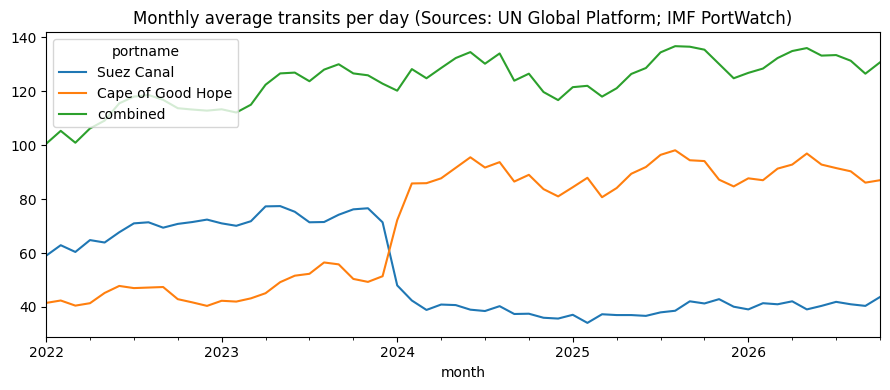

portname,Cape of Good Hope,Suez Canal,combined,combined_vs_baseline_pct
month,,,,
2025-09-01,94.4,42.1,136.5,11.5
2025-10-01,94.1,41.3,135.4,10.6
2025-11-01,87.2,42.9,130.1,6.2
2025-12-01,84.7,40.1,124.8,1.9
2026-01-01,87.7,39.1,126.8,3.5
2026-02-01,87.0,41.4,128.4,4.9
2026-03-01,91.3,41.0,132.3,8.0
2026-04-01,92.8,42.1,134.9,10.2
2026-05-01,96.9,39.1,136.0,11.1


In [3]:
import matplotlib.pyplot as plt
Q3 = """
SELECT date_trunc('month', date) AS month, portname, ROUND(AVG(n_total), 1) AS avg_per_day
FROM daily
WHERE portname IN ('Suez Canal', 'Cape of Good Hope') AND date >= DATE '2022-01-01'
GROUP BY 1, 2 ORDER BY 1, 2
"""
m = con.sql(Q3).df().pivot(index="month", columns="portname", values="avg_per_day")
m["combined"] = m["Suez Canal"] + m["Cape of Good Hope"]
base = m.loc["2023-01-01":"2023-10-31", "combined"].mean()
m["combined_vs_baseline_pct"] = (100 * (m["combined"] / base - 1)).round(1)
print("baseline combined (avg per day, Jan-Oct 2023):", round(base, 1))
m[["Suez Canal", "Cape of Good Hope", "combined"]].plot(figsize=(9, 4), title="Monthly average transits per day (Sources: UN Global Platform; IMF PortWatch)")
plt.tight_layout(); plt.show()
m.tail(14)

**Reading the monthly table and chart (data through 2026-10-11).** Suez and the Cape of Good Hope swap places in January 2024, but their combined monthly count shows no step at that point. Since then it has run between +2% and +11% above its Jan-Oct 2023 baseline (122.5 transits a day), inside the 100-130 range it already moved through in 2022-23. This is consistent with ships switching between the two routes. It does not show that the same ships moved: both routes also carry other traffic, and the combined count rose over 2022-23. The latest month is partial; values are daily averages. All counts are AIS-observed transits in PortWatch.

## D. Date the Shifts Using a 28-Day Average

In [4]:
f = daily.copy()
RULES = {"Suez Canal": ("2023-01-01", "2023-10-31", "down"), "Bab el-Mandeb Strait": ("2023-01-01", "2023-10-31", "down"),
         "Cape of Good Hope": ("2023-01-01", "2023-10-31", "up"), "Strait of Hormuz": ("2025-01-01", "2026-01-31", "down")}
out = []
for name, (a, b, way) in RULES.items():
    s = f[f.portname == name].set_index("date").n_total
    base_ = s[a:b].mean(); r = s.rolling(28).mean().loc[b:]
    row = {"chokepoint": name, "baseline_avg": round(base_, 1)}
    for k, lvl in enumerate((0.75, 0.5) if way == "down" else (1.25, 1.5), 1):
        hit = r[r < lvl * base_] if way == "down" else r[r > lvl * base_]
        row[f"level_{k}"] = f"{'below' if way == 'down' else 'above'} {int(lvl * 100)}% of baseline"
        row[f"first_day_{k}"] = str(hit.index[0].date()) if len(hit) else "not reached"
    out.append(row)
pd.DataFrame(out)

,chokepoint,baseline_avg,level_1,first_day_1,level_2,first_day_2
0,Suez Canal,73.6,below 75% of baseline,2024-01-19,below 50% of baseline,2024-07-18
1,Bab el-Mandeb Strait,74.6,below 75% of baseline,2024-01-09,below 50% of baseline,2024-02-04
2,Cape of Good Hope,48.9,above 125% of baseline,2024-01-11,above 150% of baseline,2024-02-03
3,Strait of Hormuz,83.4,below 75% of baseline,2026-01-31,below 50% of baseline,2026-03-17


**Reading the shift dates (28-day average).** Bab el-Mandeb crossed 75% of baseline on 2024-01-09, the Cape crossed 125% on 2024-01-11, and Suez crossed 75% on 2024-01-19, all within about 10 days. A 28-day average lags the underlying change by up to a couple of weeks, so these are not the dates the change began. Two entries are not valid shift dates: Hormuz's first level (2026-01-31) is the first day searched, because Hormuz traffic had already fallen below that level inside the baseline window; and Suez's 50% date (2024-07-18) is noise, because Suez settled near 55% of baseline. Section E repeats this with a 7-day average and a guard against the first problem.

## E. Date the Shifts Using a 7-Day Average

In [5]:
RULES = {"Suez Canal": ("2023-01-01", "2023-10-31", "down"), "Bab el-Mandeb Strait": ("2023-01-01", "2023-10-31", "down"),
         "Cape of Good Hope": ("2023-01-01", "2023-10-31", "up"), "Strait of Hormuz": ("2025-01-01", "2026-01-31", "down")}
out = []
for name, (a, b, way) in RULES.items():
    s = f[f.portname == name].set_index("date").n_total
    base_ = s[a:b].mean()
    r7 = s.rolling(7).mean().loc[pd.Timestamp(b) + pd.Timedelta(days=1):]
    row = {"chokepoint": name, "direction": way}
    for k, lv in enumerate((0.75, 0.5, 0.25) if way == "down" else (1.25, 1.5, 2.0), 1):
        cond = (r7 < lv * base_) if way == "down" else (r7 > lv * base_)
        row[f"date_level_{k}"] = "already at start" if cond.iloc[0] else (str(cond[cond].index[0].date()) if cond.any() else "not reached")
    out.append(row)
print("legend: down = 75% / 50% / 25% of baseline; up = 125% / 150% / 200% of baseline")
pd.DataFrame(out)

legend: down = 75% / 50% / 25% of baseline; up = 125% / 150% / 200% of baseline


,chokepoint,direction,date_level_1,date_level_2,date_level_3
0,Suez Canal,down,2024-01-06,2024-03-06,not reached
1,Bab el-Mandeb Strait,down,2023-12-23,2024-01-18,not reached
2,Cape of Good Hope,up,2024-01-01,2024-01-08,2024-04-18
3,Strait of Hormuz,down,already at start,2026-03-04,2026-03-06


**Reading the 7-day shift dates.** With a 7-day average, Bab el-Mandeb crossed 75% of baseline on 2023-12-23, the Cape of Good Hope crossed 125% on 2024-01-01 and Suez crossed 75% on 2024-01-06, a spread of about two weeks. The cluster in late December 2023 to early January 2024 is similar to the 28-day result, so the finding does not depend on the averaging window. The dates mark when the average first crossed each line, so the underlying changes may have started a few days earlier. Second-level entries for Suez (50%, 2024-03-06) and the Cape (200%, 2024-04-18) are not shift dates: those levels sit close to where the series settled, so brief swings crossed them. For Hormuz, the first level was already crossed at the start of the search; its average fell from below 50% to below 25% of baseline between 2026-03-04 and 2026-03-06, a sudden drop. I have not linked any of these dates to outside events.

## F. Build the Hormuz Timeline

In [6]:
h = daily[daily.portname == "Strait of Hormuz"].set_index("date").n_total
base = h["2025-01-01":"2026-01-31"].mean()
r7 = h.rolling(7).mean()
after = r7["2026-02-01":]
collapse = after[after < 0.25 * base].index[0]
trough_day = after.loc[collapse:].idxmin()
post = r7.loc[trough_day:]
peak_day = post.idxmax()
rows = [("Baseline average (Jan 2025-Jan 2026)", None, base),
        ("7-day average first below 25% of baseline", collapse, r7[collapse]),
        ("Lowest 7-day average since then", trough_day, r7[trough_day]),
        ("Highest 7-day average after that low", peak_day, r7[peak_day]),
        ("Latest 7-day average", r7.index[-1], r7.iloc[-1])]
timeline = pd.DataFrame([{"point": p, "date": "" if d is None else str(d.date()), "transits_per_day": round(v, 1), "pct_of_baseline": round(100 * v / base, 1)} for p, d, v in rows])
display(timeline)

mh = con.sql("""SELECT date_trunc('month', date) AS month, ROUND(AVG(n_total), 1) AS avg_per_day FROM daily
                WHERE portname = 'Strait of Hormuz' AND date >= DATE '2025-06-01' GROUP BY 1 ORDER BY 1""").df()
mh

,point,date,transits_per_day,pct_of_baseline
0,Baseline average (Jan 2025-Jan 2026),,83.4,100.0
1,7-day average first below 25% of baseline,2026-03-06,12.9,15.4
2,Lowest 7-day average since then,2026-05-09,1.3,1.5
3,Highest 7-day average after that low,2026-06-29,31.9,38.2
4,Latest 7-day average,2026-10-11,4.1,5.0


,month,avg_per_day
0,2025-06-01,102.2
1,2025-07-01,95.2
2,2025-08-01,94.5
3,2025-09-01,87.9
4,2025-10-01,89.4
5,2025-11-01,67.4
6,2025-12-01,55.5
7,2026-01-01,58.5
8,2026-02-01,78.3
9,2026-03-01,3.2


**Reading the Hormuz timeline (data through 2026-10-11).** Against a baseline of 83.4 transits a day, the 7-day average first fell below 25% of baseline on 2026-03-06 (12.9 a day); monthly averages dropped from 78.3 in February to 3.2 in March. The lowest 7-day average was 1.3 a day on 2026-05-09 (1.5% of baseline). A partial recovery peaked at 31.9 a day on 2026-06-29 (38.2% of baseline), then faded: monthly averages were 12.9 in June and 10.2 in July, and about 4 from August to October. The latest 7-day average is 4.1 a day (5.0% of baseline). The pre-collapse period is not one level: monthly averages were about 88-102 in mid-2025, 55-67 from November 2025 to January 2026 and 78 in February 2026, so the baseline mixes a high and a low stretch; the headline change is similar under other baselines (see notebook 02). PortWatch's counts are AIS-observed. Lloyd's List Intelligence's 8 October 2026 brief reports September as the highest month for non-Iranian-linked transits since the conflict began, whereas PortWatch's September average is below June and July; the two sources use different scope and definitions, and I have not tested why they differ.